# A motion-centric encoder: TimeSformer fine-tuned on Something-Something v2 (target: official level)

TimeSformer K600 (our best) was fine-tuned on Kinetics, which can largely be solved from scenes and objects.
Something-Something v2 can only be solved from how things move ("pushing X left" vs "pulling X right"), so the same
architecture fine-tuned on it should encode movement rather than appearance. The pose oracle and the failed 1 Hz motion
statistics both point at sub-second movement as what our features miss.

`facebook/timesformer-base-finetuned-ssv2`, same framing as K600 (whole frame squashed to 224, ego + best exo, same
cameras), but 8 frames at **4 FPS = 2 s clips**, closer to SSv2's temporal scale (8 frames over a 2-6 s clip). Per
clip: layers 6 and 12, CLS / patch-token mean / patch-token std; take = mean over clips.

Protocol as `motion_stats.ipynb`: all 2,111 official takes, 4 x 5-fold StratifiedGroupKFold by participant,
scenario-centered PCA-64 per block inside the fold, scenario one-hot; within-scenario Spearman (ridge), accuracy and
balanced accuracy (4-class logistic); participant bootstrap, paired against K600 ego+exo. Then the official split.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from scipy.stats import spearmanr

DATA_ROOT = next(p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir())
ANNOTATION_ROOT = DATA_ROOT / "annotations"
LEVELS = {"Novice": 1, "Early Expert": 2, "Intermediate Expert": 3, "Late Expert": 4}
meta = {}
for split_name, fname in (("train", "proficiency_demonstrator_train.json"), ("val", "proficiency_demonstrator_val.json")):
    for m in json.loads((ANNOTATION_ROOT / fname).read_text(encoding="utf-8"))["annotations"]:
        meta[m["video_paths"]["ego"].split("/")[1]] = dict(split=split_name, scenario=m["scenario_name"],
                                                           score=LEVELS[m["proficiency_score"]], participant=m["origin_participant_id"])
E = Path("embeddings")
def caches(files):
    out, cams = {}, {}
    for name in files:
        c = torch.load(E / name, mmap=True)
        out.update({t: x for t, x in c["clips"]["squash"].items() if t in meta})
        cams.update(c["camera"])
    return out, cams
CLIPS, CAMS = {}, {}
for view in ("exo", "ego"):
    CLIPS[("K600", view)], CAMS[("K600", view)] = caches([f"timesformer_k600_{view}8fps_clips.pt", f"timesformer_k600_{view}8fps_clips_extra.pt"])
    CLIPS[("SSv2", view)], CAMS[("SSv2", view)] = caches([f"timesformer_ssv2_{view}4fps_clips.pt"])
names = sorted(t for t in meta if all(t in c for c in CLIPS.values()))
same_cam = np.mean([CAMS[("K600", "exo")][t] == CAMS[("SSv2", "exo")][t] for t in names])
split = np.array([meta[t]["split"] for t in names])
scores = np.array([meta[t]["score"] for t in names])
scenarios = np.array([meta[t]["scenario"] for t in names])
participants = np.array([meta[t]["participant"] for t in names])
SCENARIO_NAMES = np.unique(scenarios)
log_duration = np.log([len(CLIPS[("K600", "exo")][t]) for t in names])
print(f"{len(names)} takes with all four caches ({dict(zip(*np.unique(split, return_counts=True)))}); "
      f"same exo camera in K600 and SSv2: {same_cam:.1%}")

STATS = {"L12 std": (1, 2), "L12 mean": (1, 1), "L12 CLS": (1, 0), "L6 std": (0, 2), "L6 mean": (0, 1)}
FEATS = {}
for (enc, view), cache in CLIPS.items():
    for stat, (l, s) in STATS.items():
        FEATS[f"{enc} {view} {stat}"] = np.stack([cache[t][:, l, s].float().mean(0).numpy() for t in names])
del CLIPS
print(len(FEATS), "feature blocks of", FEATS["SSv2 exo L12 std"].shape)

2111 takes with all four caches ({np.str_('train'): np.int64(1655), np.str_('val'): np.int64(456)}); same exo camera in K600 and SSv2: 100.0%


20 feature blocks of (2111, 768)


#### Cross-validation over all official takes

In [2]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegressionCV, RidgeCV
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler

N_REPEATS, N_FOLDS, PCA_DIMS = 4, 5, 64

def within_scenario(x, scen):
    x = np.asarray(x, float).copy()
    for s in np.unique(scen):
        m = scen == s
        x[m] -= np.nanmean(x[m])
    return x
level_c = within_scenario(scores, scenarios)

def block_matrix(key, fit):
    fitmask = np.zeros(len(names), bool); fitmask[fit] = True
    if key == "duration":
        d = log_duration[:, None].copy()
        for s in SCENARIO_NAMES:
            m = scenarios == s
            d[m] -= d[fitmask & m].mean()
        return np.hstack([d * (scenarios == s)[:, None] for s in SCENARIO_NAMES])
    X = FEATS[key].astype(np.float64).copy()
    for s in SCENARIO_NAMES:
        m = scenarios == s
        X[m] -= X[fitmask & m].mean(0)
    return PCA(PCA_DIMS, svd_solver="full").fit(X[fit]).transform(X)

def ee(enc, stat="L12 std"):
    return [f"{enc} ego {stat}", f"{enc} exo {stat}"]
METHODS = {
    "scenario only": [],
    "duration only": ["duration"],
    "K600 exo": ["K600 exo L12 std"],
    "K600 ego": ["K600 ego L12 std"],
    "K600 ego+exo (current best)": ee("K600"),
    "SSv2 exo": ["SSv2 exo L12 std"],
    "SSv2 ego": ["SSv2 ego L12 std"],
    "SSv2 ego+exo": ee("SSv2"),
    "SSv2 ego+exo, L12 mean": ee("SSv2", "L12 mean"),
    "SSv2 ego+exo, L12 CLS": ee("SSv2", "L12 CLS"),
    "SSv2 ego+exo, L6 std": ee("SSv2", "L6 std"),
    "SSv2 ego+exo, L6 mean": ee("SSv2", "L6 mean"),
    "K600 + SSv2 exo": ["K600 exo L12 std", "SSv2 exo L12 std"],
    "K600 + SSv2 ego+exo": ee("K600") + ee("SSv2"),
}

def fit_predict(blocks, fit, held, cache):
    onehot = OneHotEncoder(handle_unknown="ignore").fit(scenarios[fit][:, None]).transform(scenarios[:, None]).toarray()
    parts = [onehot]
    for b in blocks:
        if b not in cache:
            cache[b] = block_matrix(b, fit)
        parts.append(cache[b])
    X = np.hstack(parts)
    X = StandardScaler().fit(X[fit]).transform(X)
    ridge = RidgeCV(alphas=np.logspace(-2, 6, 17)).fit(X[fit], scores[fit])
    logit = LogisticRegressionCV(Cs=np.logspace(-4, 2, 7), cv=5, max_iter=5000, n_jobs=-1).fit(X[fit], scores[fit])
    return ridge.predict(X[held]), logit.predict(X[held])

cont = {m: np.full((N_REPEATS, len(names)), np.nan) for m in METHODS}
label = {m: np.zeros((N_REPEATS, len(names)), int) for m in METHODS}
fold_of = np.zeros((N_REPEATS, len(names)), int)
for repeat in range(N_REPEATS):
    folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=repeat).split(np.zeros(len(names)), scores, participants)
    for fold, (fit, held) in enumerate(folds):
        fold_of[repeat, held] = fold
        cache = {}
        for m, blocks in METHODS.items():
            cont[m][repeat, held], label[m][repeat, held] = fit_predict(blocks, fit, held, cache)
    print(f"repeat {repeat + 1} done", flush=True)

repeat 1 done


repeat 2 done


repeat 3 done


repeat 4 done


In [3]:
N_BOOTSTRAP = 1000
def centered(c):
    out = c.copy()
    for r in range(N_REPEATS):
        for f in range(N_FOLDS):
            for s in SCENARIO_NAMES:
                g = (fold_of[r] == f) & (scenarios == s)
                out[r, g] -= c[r, g].mean()
    return out.mean(0)
P = {m: centered(v) for m, v in cont.items()}
HIT = {m: (label[m] == scores).mean(0) for m in METHODS}
upart = np.unique(participants)
rows_of = {p: np.flatnonzero(participants == p) for p in upart}
boot = np.random.default_rng(0)
res = [np.concatenate([rows_of[p] for p in boot.choice(upart, len(upart))]) for _ in range(N_BOOTSTRAP)]
def sp(a, b):
    return spearmanr(a, b)[0] if np.std(a) > 1e-12 else 0.0
R = {m: {"rho": (sp(P[m], level_c), np.array([sp(P[m][r], level_c[r]) for r in res])),
         "acc": (HIT[m].mean(), np.array([HIT[m][r].mean() for r in res])),
         "bal": np.mean([balanced_accuracy_score(scores, label[m][r]) for r in range(N_REPEATS)])} for m in METHODS}
def ci(m, k):
    v, b = R[m][k]
    return f"{v:.3f} [{np.quantile(b, .025):.3f}, {np.quantile(b, .975):.3f}]"
print(f"{'method':<32}{'Spearman (within scenario)':>28}{'accuracy':>24}{'balanced':>10}")
for m in METHODS:
    print(f"{m:<32}{ci(m, 'rho'):>28}{ci(m, 'acc'):>24}{R[m]['bal']:>10.3f}")
def diff(a, b, k):
    d = R[a][k][1] - R[b][k][1]
    lo, hi = np.quantile(d, [0.025, 0.975])
    return f"{R[a][k][0] - R[b][k][0]:+.3f} [{lo:+.3f}, {hi:+.3f}]" + (" *" if lo > 0 or hi < 0 else "  ")
print("\npaired differences (* = 95% participant-bootstrap CI excludes 0)")
for a, b in [("SSv2 ego+exo", "K600 ego+exo (current best)"), ("SSv2 exo", "K600 exo"), ("SSv2 ego", "K600 ego"),
             ("K600 + SSv2 ego+exo", "K600 ego+exo (current best)"), ("K600 + SSv2 exo", "K600 exo")]:
    print(f"  {a + ' - ' + b:<58} Spearman {diff(a, b, 'rho')}   accuracy {diff(a, b, 'acc')}")
print("\nper scenario, within-scenario Spearman")
show = ["duration only", "K600 ego+exo (current best)", "SSv2 ego+exo", "K600 + SSv2 ego+exo"]
tab = pd.DataFrame({m: {s: sp(P[m][scenarios == s], level_c[scenarios == s]) for s in SCENARIO_NAMES} for m in show})
tab.insert(0, "n", [int((scenarios == s).sum()) for s in SCENARIO_NAMES])
print(tab.round(3).to_string())

method                            Spearman (within scenario)                accuracy  balanced
scenario only                           0.000 [0.000, 0.000]    0.366 [0.307, 0.433]     0.330
duration only                           0.159 [0.081, 0.243]    0.361 [0.308, 0.425]     0.323
K600 exo                                0.412 [0.274, 0.531]    0.351 [0.312, 0.391]     0.332
K600 ego                                0.352 [0.258, 0.442]    0.350 [0.309, 0.394]     0.315
K600 ego+exo (current best)             0.452 [0.334, 0.559]    0.386 [0.339, 0.435]     0.367
SSv2 exo                                0.367 [0.226, 0.490]    0.351 [0.308, 0.393]     0.329
SSv2 ego                                0.332 [0.249, 0.409]    0.351 [0.311, 0.398]     0.317
SSv2 ego+exo                            0.405 [0.281, 0.520]    0.368 [0.324, 0.413]     0.352
SSv2 ego+exo, L12 mean                  0.413 [0.301, 0.515]    0.376 [0.335, 0.423]     0.353
SSv2 ego+exo, L12 CLS                   0.383 [0.2

#### Official split (train 1,655 -> val)

In [4]:
with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as f:
    sf_test = {json.loads(line)["video_paths"][0].split("/")[1] for line in f}
o_fit, o_val = np.flatnonzero(split == "train"), np.flatnonzero(split == "val")
EVALS = {"full val": o_val, "SkillFormer test half": o_val[np.isin(np.array(names)[o_val], list(sf_test))]}
OFFICIAL = ["scenario only", "duration only", "K600 ego+exo (current best)", "SSv2 exo", "SSv2 ego", "SSv2 ego+exo", "K600 + SSv2 ego+exo"]
cache, o_out = {}, {}
for m in OFFICIAL:
    o_out[m] = fit_predict(METHODS[m], o_fit, np.arange(len(names)), cache)
ob = np.random.default_rng(0)
REF = "K600 ego+exo (current best)"
for ev, idx in EVALS.items():
    y, sc, pt = scores[idx], scenarios[idx], participants[idx]
    lc = within_scenario(y, sc)
    up = np.unique(pt); ro = {p: np.flatnonzero(pt == p) for p in up}
    rs = [np.concatenate([ro[p] for p in ob.choice(up, len(up))]) for _ in range(N_BOOTSTRAP)]
    print(f"\n-- {ev} (n={len(idx)}, {len(up)} participants)")
    print(f"{'method':<32}{'accuracy':>24}{'balanced':>10}{'Spearman (within scenario)':>30}")
    B = {}
    for m in OFFICIAL:
        c, l = within_scenario(o_out[m][0][idx], sc), o_out[m][1][idx]
        hit = (l == y).astype(float)
        ab, rb = np.array([hit[r].mean() for r in rs]), np.array([sp(c[r], lc[r]) for r in rs])
        B[m] = (hit.mean(), ab, sp(c, lc), rb)
        print(f"{m:<32}{hit.mean():>8.3f} [{np.quantile(ab, .025):.3f}, {np.quantile(ab, .975):.3f}]{balanced_accuracy_score(y, l):>10.3f}"
              f"{sp(c, lc):>+14.3f} [{np.quantile(rb, .025):+.3f}, {np.quantile(rb, .975):+.3f}]")
    for a in ("SSv2 ego+exo", "K600 + SSv2 ego+exo"):
        da, dr = B[a][1] - B[REF][1], B[a][3] - B[REF][3]
        print(f"  {a + ' - K600 ego+exo':<40} accuracy {B[a][0] - B[REF][0]:+.3f} [{np.quantile(da, .025):+.3f}, {np.quantile(da, .975):+.3f}]"
              f"   Spearman {B[a][2] - B[REF][2]:+.3f} [{np.quantile(dr, .025):+.3f}, {np.quantile(dr, .975):+.3f}]")


-- full val (n=456, 56 participants)
method                                          accuracy  balanced    Spearman (within scenario)
scenario only                      0.314 [0.182, 0.471]     0.332        +0.000 [+0.000, +0.000]
duration only                      0.452 [0.302, 0.611]     0.373        +0.162 [-0.011, +0.351]


K600 ego+exo (current best)        0.452 [0.322, 0.591]     0.412        +0.369 [+0.114, +0.594]
SSv2 exo                           0.408 [0.279, 0.552]     0.346        +0.274 [+0.006, +0.536]


SSv2 ego                           0.432 [0.329, 0.557]     0.390        +0.187 [-0.064, +0.432]
SSv2 ego+exo                       0.388 [0.272, 0.527]     0.375        +0.287 [+0.015, +0.543]


K600 + SSv2 ego+exo                0.434 [0.304, 0.576]     0.390        +0.328 [+0.063, +0.576]
  SSv2 ego+exo - K600 ego+exo              accuracy -0.064 [-0.126, -0.002]   Spearman -0.082 [-0.176, +0.018]
  K600 + SSv2 ego+exo - K600 ego+exo       accuracy -0.018 [-0.052, +0.021]   Spearman -0.041 [-0.103, +0.017]

-- SkillFormer test half (n=229, 53 participants)
method                                          accuracy  balanced    Spearman (within scenario)
scenario only                      0.319 [0.180, 0.475]     0.349        +0.000 [+0.000, +0.000]
duration only                      0.459 [0.296, 0.620]     0.386        +0.084 [-0.116, +0.306]


K600 ego+exo (current best)        0.437 [0.300, 0.592]     0.379        +0.372 [+0.079, +0.629]
SSv2 exo                           0.393 [0.241, 0.547]     0.355        +0.276 [-0.030, +0.556]


SSv2 ego                           0.463 [0.362, 0.589]     0.440        +0.249 [-0.014, +0.481]
SSv2 ego+exo                       0.380 [0.245, 0.527]     0.347        +0.302 [+0.004, +0.582]


K600 + SSv2 ego+exo                0.415 [0.273, 0.573]     0.360        +0.334 [+0.033, +0.611]
  SSv2 ego+exo - K600 ego+exo              accuracy -0.057 [-0.124, +0.009]   Spearman -0.070 [-0.197, +0.040]
  K600 + SSv2 ego+exo - K600 ego+exo       accuracy -0.022 [-0.075, +0.034]   Spearman -0.038 [-0.109, +0.019]


#### Figure

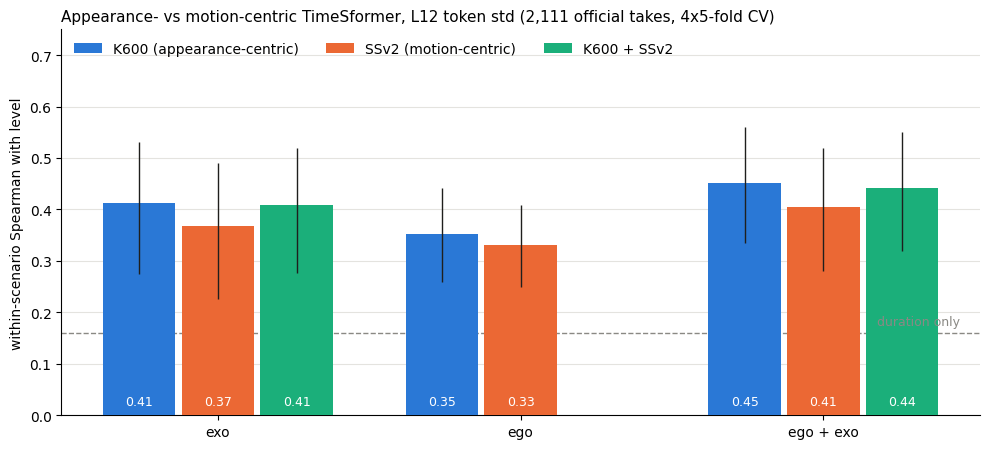

In [5]:
import matplotlib.pyplot as plt
groups = [("exo", "K600 exo", "SSv2 exo", "K600 + SSv2 exo"), ("ego", "K600 ego", "SSv2 ego", None),
          ("ego + exo", "K600 ego+exo (current best)", "SSv2 ego+exo", "K600 + SSv2 ego+exo")]
series = [(1, "K600 (appearance-centric)", "#2a78d6"), (2, "SSv2 (motion-centric)", "#eb6834"), (3, "K600 + SSv2", "#1baf7a")]
fig, ax = plt.subplots(figsize=(10, 4.6))
w = 0.26
for k, (col, lab, color) in enumerate(series):
    for j, g in enumerate(groups):
        m = g[col]
        if m is None:
            continue
        x = j + (k - 1) * w
        v, b = R[m]["rho"]
        lo, hi = np.quantile(b, [.025, .975])
        ax.bar(x, v, w * 0.92, color=color, label=lab if j == 0 else None, zorder=3)
        ax.errorbar(x, v, yerr=[[v - lo], [hi - v]], fmt="none", ecolor="#1f1f1d", elinewidth=1, zorder=4)
        ax.text(x, 0.015, f"{v:.2f}", ha="center", va="bottom", fontsize=9, color="white", zorder=5)
ax.axhline(R["duration only"]["rho"][0], color="#8a8984", lw=1, ls="--", zorder=2)
ax.text(2.45, R["duration only"]["rho"][0] + 0.01, "duration only", ha="right", va="bottom", fontsize=9, color="#8a8984")
ax.set_xticks(range(len(groups)), [g[0] for g in groups])
ax.set_ylabel("within-scenario Spearman with level")
ax.set_ylim(0, 0.75)
ax.grid(axis="y", color="#e4e3df", zorder=0)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper left", ncol=3)
ax.set_title(f"Appearance- vs motion-centric TimeSformer, L12 token std ({len(names):,} official takes, 4x5-fold CV)", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig("figures/ssv2_encoder.png", dpi=150)
plt.show()